# **Import Python Libraries**

In [449]:
# Data manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, NullLocator
import seaborn as sns
import missingno as mso

# Data Cleaning
import re
import unicodedata

# Data preprocessing
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from imblearn.over_sampling import SMOTE

# Data modelling
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, RepeatedStratifiedKFold

# Model evaluation
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report)

# 1. Import Data

In [450]:
data = pd.read_csv("Data/DATA WORLWIDE EOR PROJECTSP(Datos EOR Limpios).csv", sep=";")
data.head()

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Profit,Source,Formation,Fluids Composition,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,Brazil,Steam Injection,27,3000,2300,13,825,124,76,succ,good,NaN,NaN,NaN,NaN,NaN,NaN,Sandstone,NaN,Volátiles (C1 - C7)
1,Brazil,Steam Injection,25,4000,1150,15,1700,100,70,succ,good,NaN,NaN,NaN,NaN,NaN,NaN,Carbonate,NaN,Fracciones pesados (C5 - C12)
2,Brazil,Steam Injection,25,3000,1480,15,2500,100,70,succ,good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Brazil,Steam Injection,22,200,2460,21,500,122,70,succ,good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Brazil,CO2 Injection,22,112,1970,35,105,120,50,succ,good,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Exploratory Data Analysis (EDA)

In [451]:
# Explore data columns

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             418 non-null    object 
 1   EOR_Method          417 non-null    object 
 2   Porosity (%)        412 non-null    object 
 3   Permeability (md)   414 non-null    object 
 4   Depth (ft)          402 non-null    object 
 5   Gravity API         399 non-null    object 
 6   Viscocity (cp)      398 non-null    object 
 7   Temperature (°F)    402 non-null    object 
 8   Oil_Saturation (%)  366 non-null    object 
 9   Project_Eval        408 non-null    object 
 10  Profit              371 non-null    object 
 11  Source              173 non-null    object 
 12  Formation           57 non-null     object 
 13  Fluids Composition  55 non-null     object 
 14  Unnamed: 14         0 non-null      float64
 15  Unnamed: 15         0 non-null      float64
 16  Unnamed:

In [452]:
# Explore null data

data.isna().sum()

Country                 0
EOR_Method              1
Porosity (%)            6
Permeability (md)       4
Depth (ft)             16
Gravity API            19
Viscocity (cp)         20
Temperature (°F)       16
Oil_Saturation (%)     52
Project_Eval           10
Profit                 47
Source                245
Formation             361
Fluids Composition    363
Unnamed: 14           418
Unnamed: 15           418
Unnamed: 16           418
Unnamed: 17           416
Unnamed: 18           418
Unnamed: 19           416
dtype: int64

In [453]:
# Drop innecessary columns

data = data.drop(columns=["Source", "Unnamed: 14", "Unnamed: 15",
                         "Unnamed: 16", "Unnamed: 17", "Unnamed: 18",
                         "Unnamed: 19", "Profit"], axis=1)

data

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition
0,Brazil,Steam Injection,27,3000,2300,13,825,124,76,succ,NaN,NaN
1,Brazil,Steam Injection,25,4000,1150,15,1700,100,70,succ,NaN,NaN
2,Brazil,Steam Injection,25,3000,1480,15,2500,100,70,succ,NaN,NaN
3,Brazil,Steam Injection,22,200,2460,21,500,122,70,succ,NaN,NaN
4,Brazil,CO2 Injection,22,112,1970,35,105,120,50,succ,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
413,Malaysia (Sabah),Chemical + CO₂ hybrid EOR,23,500-1000,9000,35-45,"0,5-2",220,70,disc,Sandstone,Volátiles (C1 - C7)
414,Malaysia (Sarawak),Gas Huff-n-Puff,23,500-1200,8500,32-42,1-5,200,70,average,Sandstone,Volátiles (C1 - C7)
415,Malaysia,Inmiscible water alternating gas,30,200,NaN,NaN,NaN,202,85,average,Sandstone,Volátiles (C1 - C7)
416,Turkey,Chemical + CO₂ hybrid EOR,15,NaN,4500,13,800,155,85,average,Carbonate,Fracciones pesados (C5 - C12)


In [454]:
# Check columns again

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country             418 non-null    object
 1   EOR_Method          417 non-null    object
 2   Porosity (%)        412 non-null    object
 3   Permeability (md)   414 non-null    object
 4   Depth (ft)          402 non-null    object
 5   Gravity API         399 non-null    object
 6   Viscocity (cp)      398 non-null    object
 7   Temperature (°F)    402 non-null    object
 8   Oil_Saturation (%)  366 non-null    object
 9   Project_Eval        408 non-null    object
 10  Formation           57 non-null     object
 11  Fluids Composition  55 non-null     object
dtypes: object(12)
memory usage: 39.3+ KB


In [455]:
# To inspect values of each class

data["EOR_Method"].value_counts(normalize=True) * 100

EOR_Method
Steam Injection                     25.419664
CO2 Injection                       22.781775
Polymer                              9.112710
HC injection                         7.194245
Combustion                           3.597122
                                      ...    
In-Situ Combustion                   0.239808
Solvent EOR (Green solvents)         0.239808
Polymer EOR (screening)              0.239808
Inmiscible water alternating gas     0.239808
Hot CO2 injection                    0.239808
Name: proportion, Length: 87, dtype: float64

# 3. Data Preprocessing

## 3.1. Data Cleaning

### 3.1.1. Check the consistency of data types

In [456]:
# Correct country column

def clean_country(value):
    """
    Example:
    'Malaysia (Sabah)'   -> 'Malaysia'
    'Malaysia (Sarawak)' -> 'Malaysia'
    """
    if pd.isna(value):
        return np.nan

    return str(value).split("(")[0].strip()

In [457]:
# Apply clean_country function

data["Country"]  = data["Country"].apply(clean_country)
data.Country.value_counts()

Country
USA           162
Canada         45
Brazil         35
Venezuela      17
China          15
Trinidad       14
Colombia       14
Norway         12
Oman           12
Germany        10
Russia          9
Kazajistan      9
Argentina       9
Kuwait          8
Nigeria         7
Malaysia        5
Egypt           5
Sudan           5
Angola          4
India           4
Suriname        4
Turquía         3
Turkey          2
Azerbaijan      2
UAE             2
Malasia         1
Rusia           1
Albania         1
Indonesia       1
Name: count, dtype: int64

In [458]:
# Correct some country names

data["Country"] = data["Country"].replace("Malasia", "Malaysia")
data["Country"] = data["Country"].replace("Rusia", "Russia")
data["Country"] = data["Country"].replace("Turquía", "Turkey")

data.Country.unique()

array(['Brazil', 'Canada', 'China', 'Egypt', 'Germany', 'India', 'Kuwait',
       'Norway', 'Turkey', 'USA', 'Venezuela', 'Malaysia', 'Kazajistan',
       'Colombia', 'Suriname', 'Oman', 'Russia', 'Sudan', 'Trinidad',
       'Angola', 'Nigeria', 'UAE', 'Albania', 'Argentina', 'Indonesia',
       'Azerbaijan'], dtype=object)

In [459]:
# Correct data types

def range_to_float(value):
    """
    Converts individual values and ranges to float.

    Examples:
    '500-1000' -> 750.0
    '35-45'    -> 40.0
    '0,5-2'    -> 1.25
    '200'      -> 200.0
    """
    if pd.isna(value):
        return np.nan

    # Convert decimal commas and different dash symbols
    text = (
        str(value)
        .strip()
        .replace(",", ".")
        .replace("–", "-")
        .replace("—", "-")
    )

    # Detect a range
    range_match = re.search(
        r"([+-]?\d+(?:\.\d+)?)\s*-\s*([+-]?\d+(?:\.\d+)?)",
        text
    )

    if range_match:
        lower = float(range_match.group(1))
        upper = float(range_match.group(2))
        return (lower + upper) / 2

    # Detect one numerical value
    number_match = re.search(r"[+-]?\d+(?:\.\d+)?", text)

    if number_match:
        return float(number_match.group())

    return np.nan

In [460]:
# Apply range_to_float function

# Columns that should contain numerical values
numeric_columns = [
    "Porosity (%)",
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

# Convert values and calculate the average of ranges
for column in numeric_columns:
    data[column] = data[column].apply(range_to_float)

data.head()

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition
0,Brazil,Steam Injection,27.0,3000.0,2300.0,13.0,825.0,124.0,76.0,succ,NaN,NaN
1,Brazil,Steam Injection,25.0,4000.0,1150.0,15.0,1700.0,100.0,70.0,succ,NaN,NaN
2,Brazil,Steam Injection,25.0,3000.0,1480.0,15.0,2500.0,100.0,70.0,succ,NaN,NaN
3,Brazil,Steam Injection,22.0,200.0,2460.0,21.0,500.0,122.0,70.0,succ,NaN,NaN
4,Brazil,CO2 Injection,22.0,112.0,1970.0,35.0,105.0,120.0,50.0,succ,NaN,NaN


In [461]:
# Check columns data types

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             418 non-null    object 
 1   EOR_Method          417 non-null    object 
 2   Porosity (%)        412 non-null    float64
 3   Permeability (md)   413 non-null    float64
 4   Depth (ft)          401 non-null    float64
 5   Gravity API         397 non-null    float64
 6   Viscocity (cp)      395 non-null    float64
 7   Temperature (°F)    402 non-null    float64
 8   Oil_Saturation (%)  366 non-null    float64
 9   Project_Eval        408 non-null    object 
 10  Formation           57 non-null     object 
 11  Fluids Composition  55 non-null     object 
dtypes: float64(7), object(5)
memory usage: 39.3+ KB


In [462]:
# Explore descriptive statistics

data.describe(include=np.number)

,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
count,412.000000,413.000000,401.000000,397.000000,395.000000,402.000000,366.000000
mean,35.090546,1222.396418,4659.091521,156.752897,6011.794785,150.036318,67.213470
std,53.590789,2193.092588,3706.114147,2326.014107,34922.550698,109.414992,46.993336
min,4.000000,0.000500,175.000000,8.000000,-40.000000,46.400000,0.000000
25%,17.000000,30.000000,1750.000000,16.000000,4.000000,100.000000,55.000000
50%,25.000000,250.000000,4330.000000,28.000000,24.000000,122.000000,65.500000
75%,30.000000,1500.000000,6500.000000,37.000000,918.000000,180.375000,75.000000
max,425.000000,15000.000000,42266.000000,46366.000000,500000.000000,1298.000000,735.000000


### 3.1.2. Check for data range inconsistencies 

In [463]:
# Analize questionable ranges

columns_to_show = [
    "Country",
    "EOR_Method",
    "Formation",
    "Porosity (%)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

suspected_values = data.loc[
    # Físicamente inválidos
    (data["Viscocity (cp)"] <= 0)
    | (data["Porosity (%)"] > 100)
    | (data["Temperature (°F)"] <= 0)
    | (data["Oil_Saturation (%)"] > 100)
    | (data["Gravity API"] > 70)
    

    # Posibles, pero extremos y sujetos a revisión
    | (data["Depth (ft)"] < 500)
    | (data["Depth (ft)"] > 30000)
    | (data["Viscocity (cp)"] > 100000)
    | (data["Temperature (°F)"] > 500)
    | (data["Oil_Saturation (%)"] <= 10), columns_to_show
]

suspected_values

,Country,EOR_Method,Formation,Porosity (%),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
7,Brazil,CO2 Injection,NaN,20.0,4000.0,394.0,12.00,156.0,50.0
8,Canada,Steam Injection,NaN,265.0,1800.0,8.0,300000.00,63.0,8.0
10,Canada,CO2 Injection,NaN,12.0,8200.0,415.0,65.00,206.0,60.0
12,Canada,Steam Injection,NaN,33.0,1600.0,10.0,500000.00,55.0,85.0
13,Canada,Steam Injection,NaN,33.0,42266.0,269.0,88373.00,1298.0,60.0
17,Canada,Steam Injection,NaN,32.0,1395.0,10.0,200000.00,55.0,70.0
19,Canada,CO2 Injection,NaN,163.0,4600.0,30.0,3.00,149.0,45.0
21,Canada,Steam Injection,NaN,325.0,1480.0,13.0,13000.00,66.0,90.0
22,Canada,Steam Injection,NaN,32.0,1600.0,12.0,200000.00,60.0,60.0
24,Canada,Steam Injection,NaN,35.0,1509.0,102.0,100000.00,55.0,70.0


In [464]:
# Set criteria to correct data ranges

porosity_corrections = {
    8: 26.5, 19: 16.3, 21: 32.5, 25: 28.5,
    34: 12.7, 35: 10.5, 37: 11.8, 38: 10.3,
    39: 9.8, 40: 10.5, 43: 42.5, 45: 30.3,
    103: 16.8, 119: 40.3, 120: 39.2, 126: 11.6,
    142: 6.5, 144: 34.5, 145: 32.5, 151: 34.8,
    168: 10.3, 200: 18.1, 201: 9.2, 203: 8.6
}

api_corrections = {
    7: 39.4, 10: 41.5, 13: 26.9, 24: 10.2,
    33: 43.2, 34: 43.6, 35: 40.9, 36: 41.1,
    37: 43.4, 38: 45.4, 39: 41.3,
    119: 12.7, 120: 13.9, 142: 12.5,
    160: 14.8, 201: 43.5,
    207: 22.8, 208: 22.8, 209: 22.8,
    232: 17.6, 234: 9.3
}

temperature_corrections = {
    13: 129.8,
    162: 100.0,
    216: 129.8
}

saturation_corrections = {
    43: 73.5,
    198: 26.5,
    203: 54.4
}


data.loc[255, "Viscocity (cp)"] = np.nan

data.loc[13, "Depth (ft)"] = np.nan

data.loc[93, "Gravity API"] = np.nan

data.loc[[8, 62], "Oil_Saturation (%)"] = np.nan

In [465]:
# Correct data ranges

data_clean = data.copy()

corrections = {
    "Porosity (%)": porosity_corrections,
    "Gravity API": api_corrections,
    "Temperature (°F)": temperature_corrections,
    "Oil_Saturation (%)": saturation_corrections
}

for column, changes in corrections.items():
    for index, new_value in changes.items():
        data_clean.loc[index, column] = new_value

data_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             418 non-null    object 
 1   EOR_Method          417 non-null    object 
 2   Porosity (%)        412 non-null    float64
 3   Permeability (md)   413 non-null    float64
 4   Depth (ft)          400 non-null    float64
 5   Gravity API         396 non-null    float64
 6   Viscocity (cp)      394 non-null    float64
 7   Temperature (°F)    402 non-null    float64
 8   Oil_Saturation (%)  364 non-null    float64
 9   Project_Eval        408 non-null    object 
 10  Formation           57 non-null     object 
 11  Fluids Composition  55 non-null     object 
dtypes: float64(7), object(5)
memory usage: 39.3+ KB


In [466]:
# Check again for data ranges inconsistencies

suspected_values = data_clean.loc[
    # Físicamente inválidos
    (data_clean["Viscocity (cp)"] <= 0)
    | (data_clean["Porosity (%)"] > 100)
    | (data_clean["Temperature (°F)"] <= 0)
    | (data_clean["Oil_Saturation (%)"] > 100)
    | (data_clean["Gravity API"] > 70)
    

    # Posibles, pero extremos y sujetos a revisión
    | (data_clean["Depth (ft)"] < 500)
    | (data_clean["Depth (ft)"] > 30000)
    | (data_clean["Viscocity (cp)"] > 100000)
    | (data_clean["Temperature (°F)"] > 500)
    | (data_clean["Oil_Saturation (%)"] <= 10), columns_to_show
]

suspected_values

,Country,EOR_Method,Formation,Porosity (%),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
8,Canada,Steam Injection,NaN,26.5,1800.0,8.0,300000.00,63.0,NaN
12,Canada,Steam Injection,NaN,33.0,1600.0,10.0,500000.00,55.0,85.0
17,Canada,Steam Injection,NaN,32.0,1395.0,10.0,200000.00,55.0,70.0
22,Canada,Steam Injection,NaN,32.0,1600.0,12.0,200000.00,60.0,60.0
60,Egypt,Water injection,NaN,35.0,365.0,36.0,NaN,239.0,50.0
69,Germany,Steam Injection,NaN,38.0,350.0,22.0,350.00,100.0,60.0
119,USA,Steam Injection,NaN,40.3,175.0,12.7,2200.00,75.0,55.0
120,USA,Steam Injection,NaN,39.2,300.0,13.9,1000.00,80.0,48.0
135,USA,Steam Injection,NaN,40.0,200.0,13.0,3500.00,82.0,60.0
216,USA,Combustion,NaN,32.0,400.0,19.0,660.00,129.8,94.0


In [467]:
# Additional data range correction

data_clean.loc[347, ["Viscocity (cp)", "Oil_Saturation (%)"]] = np.nan

data_clean.loc[60, "Temperature (°F)"] = np.nan

data_clean.head()

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition
0,Brazil,Steam Injection,27.0,3000.0,2300.0,13.0,825.0,124.0,76.0,succ,NaN,NaN
1,Brazil,Steam Injection,25.0,4000.0,1150.0,15.0,1700.0,100.0,70.0,succ,NaN,NaN
2,Brazil,Steam Injection,25.0,3000.0,1480.0,15.0,2500.0,100.0,70.0,succ,NaN,NaN
3,Brazil,Steam Injection,22.0,200.0,2460.0,21.0,500.0,122.0,70.0,succ,NaN,NaN
4,Brazil,CO2 Injection,22.0,112.0,1970.0,35.0,105.0,120.0,50.0,succ,NaN,NaN


In [468]:
suspected_values = data_clean.loc[
    # Físicamente inválidos
    (data_clean["Viscocity (cp)"] <= 0)
    | (data_clean["Porosity (%)"] > 100)
    | (data_clean["Temperature (°F)"] <= 0)
    | (data_clean["Oil_Saturation (%)"] > 100)
    | (data_clean["Gravity API"] > 70)
    

    # Posibles, pero extremos y sujetos a revisión
    | (data_clean["Depth (ft)"] < 500)
    | (data_clean["Depth (ft)"] > 30000)
    | (data_clean["Viscocity (cp)"] > 100000)
    | (data_clean["Temperature (°F)"] > 500)
    | (data_clean["Oil_Saturation (%)"] <= 10), columns_to_show
]

suspected_values

,Country,EOR_Method,Formation,Porosity (%),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
8,Canada,Steam Injection,NaN,26.5,1800.0,8.0,300000.0,63.0,NaN
12,Canada,Steam Injection,NaN,33.0,1600.0,10.0,500000.0,55.0,85.0
17,Canada,Steam Injection,NaN,32.0,1395.0,10.0,200000.0,55.0,70.0
22,Canada,Steam Injection,NaN,32.0,1600.0,12.0,200000.0,60.0,60.0
60,Egypt,Water injection,NaN,35.0,365.0,36.0,NaN,NaN,50.0
69,Germany,Steam Injection,NaN,38.0,350.0,22.0,350.0,100.0,60.0
119,USA,Steam Injection,NaN,40.3,175.0,12.7,2200.0,75.0,55.0
120,USA,Steam Injection,NaN,39.2,300.0,13.9,1000.0,80.0,48.0
135,USA,Steam Injection,NaN,40.0,200.0,13.0,3500.0,82.0,60.0
216,USA,Combustion,NaN,32.0,400.0,19.0,660.0,129.8,94.0


### 3.1.3. Check for duplicates

In [469]:
columns = ["Country", "EOR_Method"] 

data_clean[data_clean.duplicated()]

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition
67,Germany,Steam Injection,30.0,10000.0,2700.0,25.0,175.0,100.0,70.0,succ,NaN,NaN
77,Kuwait,NO ENCUENTRO EL PAPER,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.1.4. Check for category inconsistencies and texts

In [470]:
# Check column names

columns = data_clean.columns.to_list()
columns

['Country',
 'EOR_Method',
 'Porosity (%)',
 'Permeability (md)',
 'Depth (ft)',
 'Gravity API',
 'Viscocity (cp)',
 'Temperature (°F)',
 'Oil_Saturation (%)',
 'Project_Eval ',
 'Formation',
 'Fluids Composition']

In [471]:
# Correct column name for Project_Eval

data_clean.columns = data_clean.columns.str.strip()

data_clean.columns

Index(['Country', 'EOR_Method', 'Porosity (%)', 'Permeability (md)',
       'Depth (ft)', 'Gravity API', 'Viscocity (cp)', 'Temperature (°F)',
       'Oil_Saturation (%)', 'Project_Eval', 'Formation',
       'Fluids Composition'],
      dtype='object')

In [472]:
# Check unique classes for each categorical variable

cols_check = ["EOR_Method", "Formation", "Project_Eval", "Fluids Composition"]

for col in cols_check:
    print(f"Unique classes of {col} column: {data_clean[col].unique()}  \n")

Unique classes of EOR_Method column: ['Steam Injection' 'CO2 Injection' 'HC injection' 'Polymer'
 'primary cold recovery technique in Canadian unconsolidated sand reservoirs.'
 'Steam injection (huff and puff)'
 'Bio-enhanced Oil Recovery and Nano-EOR'
 'Surfactant-Assisted CO2 Huff-n-Puff ' 'nano-oil-displacing agent'
 'bio-nano-materials' 'Microbial EOR' 'Water injection'
 'NO ENCUENTRO EL PAPER' 'Water injection and Alkaline Surfactant Polymer'
 'Water and steam injection' 'Polymer water' 'Foam-Assisted WAG' 'WAG'
 'water injection ' 'Combustion' 'Hot water injection '
 'Sour gas injection ' nan 'nano-oil-displacing-agent' 'Nanofluids'
 'In-situ Combustion' 'Surfactant Alternating Gas' 'CO₂-WAG'
 'Steam Injection (huff and puff)' 'Surfactant' 'Surfactant-polymer' 'ASP'
 'Polymer flooding' 'Foam-assisted water-gas flooding'
 'Huff-n-puff gas injection' 'N2 injection' 'Alkaline' 'SAGD'
 'CO₂-fracturing' 'CO₂ miscible flooding' 'CO₂ injection'
 'CO₂-EGR (gas displacement)' 'Steam flood

In [473]:
# Check values for each class of EOR_Method

len(data_clean.EOR_Method.unique())

88

In [474]:
# Clean EOR_Method column

# Exact category names displayed in the EORgui screening table
EOR_GUI_CLASSES = {
    "Nitrogen and flue gas",
    "Hydrocarbon",
    "Carbon Dioxide",
    "Immiscible Gases",
    "Miscellar/polymer, ASP, and alkaline flooding",
    "Polymer flooding",
    "Combustion",
    "Steam"
}


# More descriptive labels requested for your analysis
EOR_DISPLAY_NAMES = {
    "Nitrogen and flue gas":
        "Nitrogen and flue gas injection",

    "Hydrocarbon":
        "Hydrocarbon injection",

    "Carbon Dioxide":
        "Carbon Dioxide injection",

    "Immiscible Gases":
        "Immiscible Gas injection",

    "Miscellar/polymer, ASP, and alkaline flooding":
        "Miscellar/polymer, ASP, and alkaline flooding",

    "Polymer flooding":
        "Polymer flooding",

    "Combustion":
        "Combustion",

    "Steam":
        "Steam injection"
}


def normalize_eor_text(value):
    """Normalize spelling, spaces, accents, CO₂ and dash symbols."""

    if pd.isna(value):
        return ""

    text = str(value).strip().lower()

    # Normalize CO₂ and different dash symbols
    text = (
        text
        .replace("₂", "2")
        .replace("–", "-")
        .replace("—", "-")
        .replace("-", " ")
    )

    # Remove accents
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character
        for character in text
        if not unicodedata.combining(character)
    )

    # Replace punctuation with spaces
    text = re.sub(r"[_/()+,:;]+", " ", text)

    # Remove repeated spaces
    return re.sub(r"\s+", " ", text).strip()


def clean_eor_gui_class(value):
    """
    Convert an original EOR method into one of the eight
    categories used by the EORgui Quick Screening table.

    Unsupported or unclear methods become NaN.
    """

    text = normalize_eor_text(value)

    if not text:
        return np.nan

    # ---------------------------------------------------------
    # 1. Carbon dioxide injection
    # Must be checked before generic gas and chemical methods.
    # ---------------------------------------------------------
    if re.search(r"\bco2\b|carbon dioxide", text):

        # CO2 storage without an EOR component is not classified
        if (
            any(term in text for term in ["storage", "ccus"])
            and not any(
                term in text
                for term in ["eor", "injection", "flood", "wag", "huff"]
            )
        ):
            return np.nan

        return "Carbon Dioxide"

    # ---------------------------------------------------------
    # 2. Nitrogen and flue-gas injection
    # ---------------------------------------------------------
    if re.search(r"\bn2\b|nitrogen|flue gas", text):
        return "Nitrogen and flue gas"

    # ---------------------------------------------------------
    # 3. Hydrocarbon injection
    # ---------------------------------------------------------
    hydrocarbon_terms = [
        "hc injection",
        "hydrocarbon",
        "natural gas",
        "rich gas",
        "sour gas",
        "methane injection",
        "lpg injection"
    ]

    if any(term in text for term in hydrocarbon_terms):
        return "Hydrocarbon"

    # ---------------------------------------------------------
    # 4. Generic gas-injection methods
    # Includes WAG when the injected gas is not identified.
    # ---------------------------------------------------------
    gas_terms = [
        "wag",
        "water alternating gas",
        "water gas flooding",
        "gas injection",
        "gas huff n puff",
        "huff n puff gas",
        "surfactant alternating gas",
        "immiscible gas"
    ]

    if any(term in text for term in gas_terms):

        # Storage studies are not EOR methods
        if any(
            term in text
            for term in ["hydrogen storage", "underground storage"]
        ):
            return np.nan

        return "Immiscible Gases"

    # ---------------------------------------------------------
    # 5. Steam injection
    # ---------------------------------------------------------
    steam_terms = [
        "steam",
        "steamflood",
        "steam flooding",
        "cyclic steam",
        "css",
        "sagd"
    ]

    if any(term in text for term in steam_terms):
        return "Steam"

    # ---------------------------------------------------------
    # 6. In-situ combustion
    # ---------------------------------------------------------
    if "combustion" in text:
        return "Combustion"

    # ---------------------------------------------------------
    # 7. Chemical flooding
    # Check before polymer-only methods.
    # ---------------------------------------------------------
    chemical_terms = [
        "asp",
        "surfactant",
        "micellar",
        "alkaline",
        "caustic",
        "chemical eor",
        "sp flooding"
    ]

    if any(term in text for term in chemical_terms):
        return "Miscellar/polymer, ASP, and alkaline flooding"

    # ---------------------------------------------------------
    # 8. Polymer flooding
    # ---------------------------------------------------------
    if "polymer" in text:
        return "Polymer flooding"

    # Unsupported, incorrect or insufficiently specified method
    return np.nan

In [475]:
# Preserve the original values

# Exact EORgui category
data_clean["EOR_GUI_Class"] = (
    data_clean["EOR_Method"]
    .apply(clean_eor_gui_class)
    .astype("category")
)

# # Descriptive name containing the word "injection"
# data["EOR_Method_Clean"] = (
#     data["EOR_GUI_Class"]
#     .map(EOR_DISPLAY_NAMES)
#     .astype("category")
# )

data_clean.head()

,Country,EOR_Method,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition,EOR_GUI_Class
0,Brazil,Steam Injection,27.0,3000.0,2300.0,13.0,825.0,124.0,76.0,succ,NaN,NaN,Steam
1,Brazil,Steam Injection,25.0,4000.0,1150.0,15.0,1700.0,100.0,70.0,succ,NaN,NaN,Steam
2,Brazil,Steam Injection,25.0,3000.0,1480.0,15.0,2500.0,100.0,70.0,succ,NaN,NaN,Steam
3,Brazil,Steam Injection,22.0,200.0,2460.0,21.0,500.0,122.0,70.0,succ,NaN,NaN,Steam
4,Brazil,CO2 Injection,22.0,112.0,1970.0,35.0,105.0,120.0,50.0,succ,NaN,NaN,Carbon Dioxide


In [476]:
# Check unique clasess for new columns related to EOR_Methods

cols = ["EOR_GUI_Class", "EOR_Method"]

for col in cols:
    print(f"Unique clasess of {col} column: {data_clean[col].unique()} \n")

Unique clasess of EOR_GUI_Class column: ['Steam', 'Carbon Dioxide', 'Hydrocarbon', 'Polymer flooding', NaN, 'Miscellar/polymer, ASP, and alkaline flooding', 'Immiscible Gases', 'Combustion', 'Nitrogen and flue gas']
Categories (8, object): ['Carbon Dioxide', 'Combustion', 'Hydrocarbon', 'Immiscible Gases', 'Miscellar/polymer, ASP, and alkaline flooding', 'Nitrogen and flue gas', 'Polymer flooding', 'Steam'] 

Unique clasess of EOR_Method column: ['Steam Injection' 'CO2 Injection' 'HC injection' 'Polymer'
 'primary cold recovery technique in Canadian unconsolidated sand reservoirs.'
 'Steam injection (huff and puff)'
 'Bio-enhanced Oil Recovery and Nano-EOR'
 'Surfactant-Assisted CO2 Huff-n-Puff ' 'nano-oil-displacing agent'
 'bio-nano-materials' 'Microbial EOR' 'Water injection'
 'NO ENCUENTRO EL PAPER' 'Water injection and Alkaline Surfactant Polymer'
 'Water and steam injection' 'Polymer water' 'Foam-Assisted WAG' 'WAG'
 'water injection ' 'Combustion' 'Hot water injection '
 'Sour g

In [477]:
# Ccheck unclassified EOR Methods

unclassified = (
    data_clean.loc[
        data_clean["EOR_GUI_Class"].isna(),
        "EOR_Method"
    ]
    .value_counts(dropna=False)
)

unclassified

EOR_Method
Water injection                                                                5
Microbial Enhanced Oil Recovery                                                4
nano-oil-displacing-agent                                                      3
NO ENCUENTRO EL PAPER                                                          3
Low salinity water injection                                                   3
EOR screening / conceptual study                                               2
Nanofluids                                                                     2
Microbial EOR                                                                  2
bio-nano-materials                                                             1
nano-oil-displacing agent                                                      1
Bio-enhanced Oil Recovery and Nano-EOR                                         1
primary cold recovery technique in Canadian unconsolidated sand reservoirs.    1
Hot water injecti

In [478]:
# Remove innecessary columns

data_clean = data_clean.drop(columns=["EOR_Method"], axis=1)

data_clean.head()

,Country,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition,EOR_GUI_Class
0,Brazil,27.0,3000.0,2300.0,13.0,825.0,124.0,76.0,succ,NaN,NaN,Steam
1,Brazil,25.0,4000.0,1150.0,15.0,1700.0,100.0,70.0,succ,NaN,NaN,Steam
2,Brazil,25.0,3000.0,1480.0,15.0,2500.0,100.0,70.0,succ,NaN,NaN,Steam
3,Brazil,22.0,200.0,2460.0,21.0,500.0,122.0,70.0,succ,NaN,NaN,Steam
4,Brazil,22.0,112.0,1970.0,35.0,105.0,120.0,50.0,succ,NaN,NaN,Carbon Dioxide


In [479]:
# Check data types

data_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Country             418 non-null    object  
 1   Porosity (%)        412 non-null    float64 
 2   Permeability (md)   413 non-null    float64 
 3   Depth (ft)          400 non-null    float64 
 4   Gravity API         396 non-null    float64 
 5   Viscocity (cp)      393 non-null    float64 
 6   Temperature (°F)    401 non-null    float64 
 7   Oil_Saturation (%)  363 non-null    float64 
 8   Project_Eval        408 non-null    object  
 9   Formation           57 non-null     object  
 10  Fluids Composition  55 non-null     object  
 11  EOR_GUI_Class       374 non-null    category
dtypes: category(1), float64(7), object(4)
memory usage: 36.8+ KB


In [480]:
# Clean Project_Eval column

def clean_project_eval(col):
    """
    Standardiza las categorías de Project_Eval.

    succ, Succ       -> Successful
    Prom, Prom.      -> Average
    Average, average -> Average
    Disc., disc      -> unsuccessful
    """

    if pd.isna(col):
        return np.nan

    # Normalizar el texto
    text = (
        str(col)
        .strip()
        .lower()
        .replace(".", "")
    )

    category_mapping = {
    "succ": "Successful",
    "prom": "Average",
    "average": "Average",
    "disc": "Unsuccessful"
    }
    

    return category_mapping.get(text, np.nan)

In [481]:
# Apply clean_project_eval col

data_clean["Project_Eval"] = (
    data_clean["Project_Eval"]
    .apply(clean_project_eval)
    .astype("category")
)

data_clean

,Country,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition,EOR_GUI_Class
0,Brazil,27.0,3000.0,2300.0,13.0,825.00,124.0,76.0,Successful,NaN,NaN,Steam
1,Brazil,25.0,4000.0,1150.0,15.0,1700.00,100.0,70.0,Successful,NaN,NaN,Steam
2,Brazil,25.0,3000.0,1480.0,15.0,2500.00,100.0,70.0,Successful,NaN,NaN,Steam
3,Brazil,22.0,200.0,2460.0,21.0,500.00,122.0,70.0,Successful,NaN,NaN,Steam
4,Brazil,22.0,112.0,1970.0,35.0,105.00,120.0,50.0,Successful,NaN,NaN,Carbon Dioxide
...,...,...,...,...,...,...,...,...,...,...,...,...
413,Malaysia,23.0,750.0,9000.0,40.0,1.25,220.0,70.0,Unsuccessful,Sandstone,Volátiles (C1 - C7),Carbon Dioxide
414,Malaysia,23.0,850.0,8500.0,37.0,3.00,200.0,70.0,Average,Sandstone,Volátiles (C1 - C7),Immiscible Gases
415,Malaysia,30.0,200.0,NaN,NaN,NaN,202.0,85.0,Average,Sandstone,Volátiles (C1 - C7),Immiscible Gases
416,Turkey,15.0,NaN,4500.0,13.0,800.00,155.0,85.0,Average,Carbonate,Fracciones pesados (C5 - C12),Carbon Dioxide


In [482]:
# Check classes of Project_Eval column

data_clean.Project_Eval.value_counts()

Project_Eval
Successful      238
Average         139
Unsuccessful     31
Name: count, dtype: int64

### 3.1.5. Check and Treat Null Data

In [483]:
# Check null data of each column

data_clean.isna().sum()

Country                 0
Porosity (%)            6
Permeability (md)       5
Depth (ft)             18
Gravity API            22
Viscocity (cp)         25
Temperature (°F)       17
Oil_Saturation (%)     55
Project_Eval           10
Formation             361
Fluids Composition    363
EOR_GUI_Class          44
dtype: int64

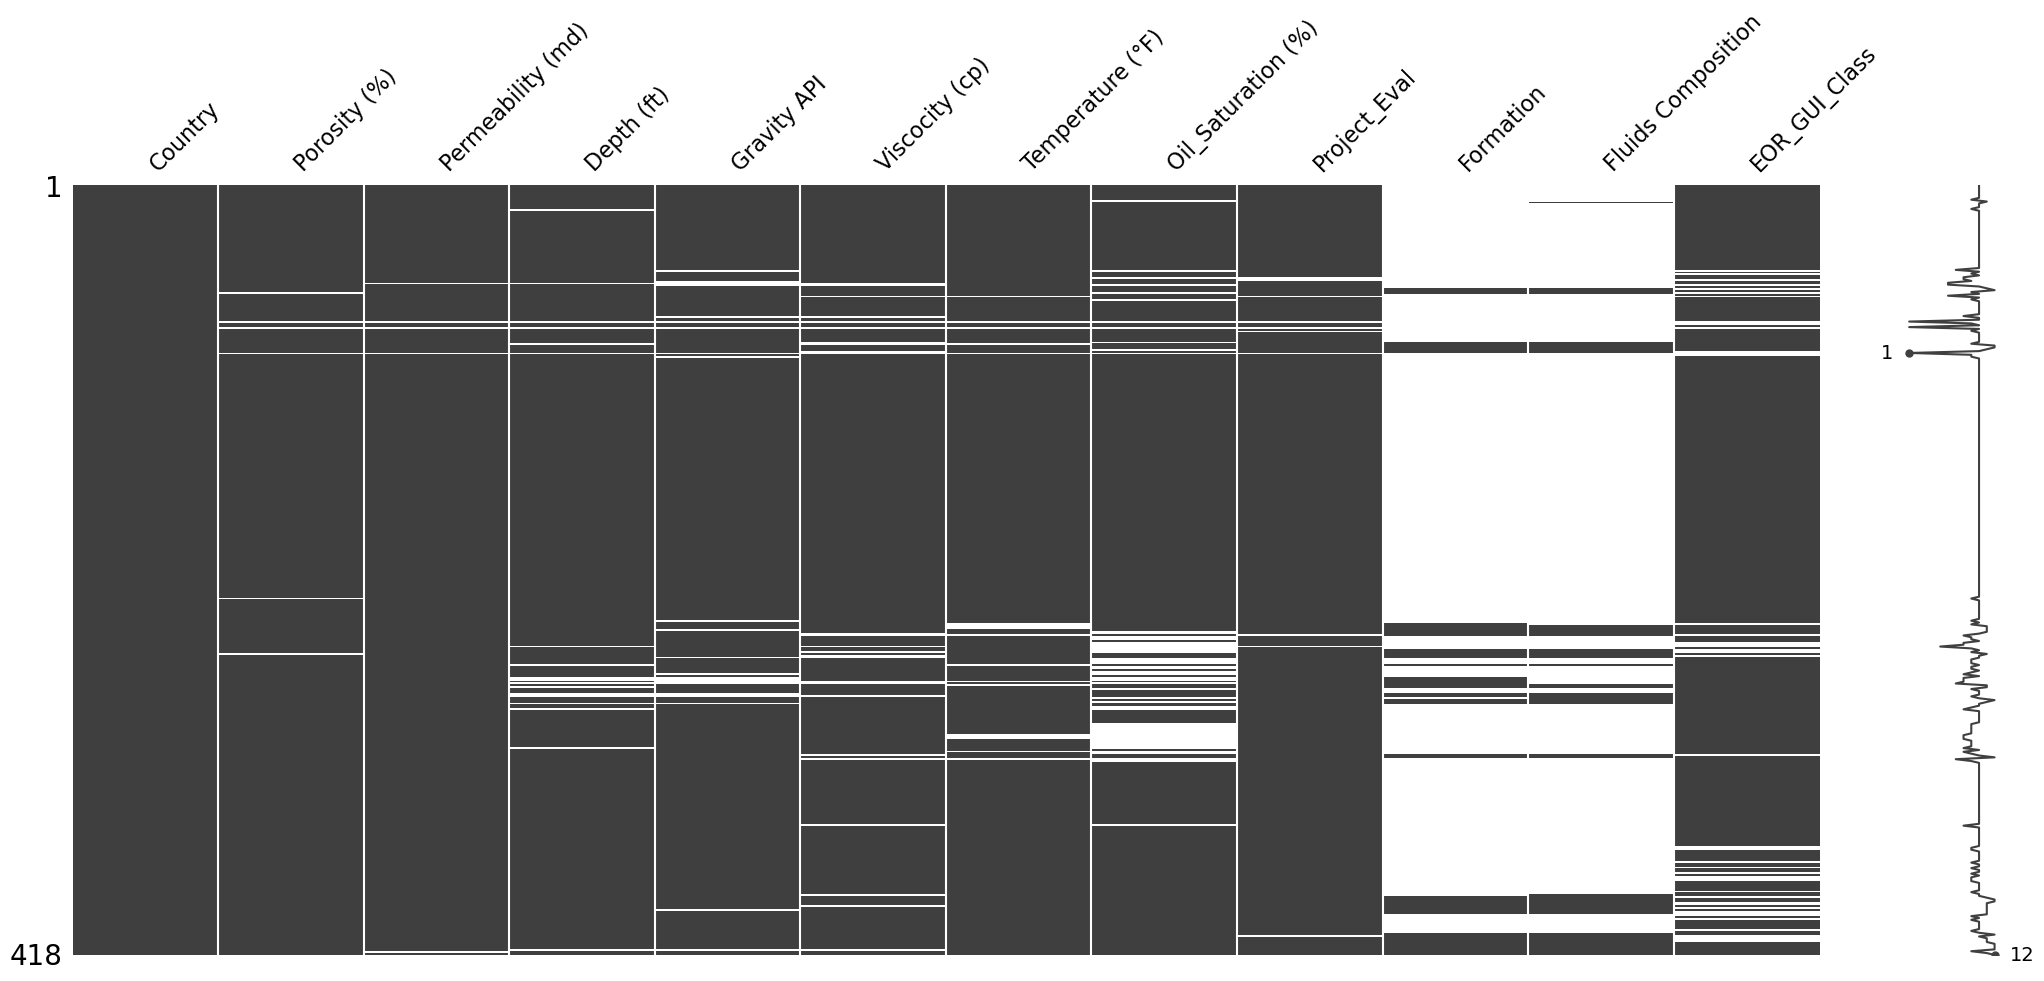

In [484]:
# Visualize null data

mso.matrix(data_clean)
plt.show()

In [485]:
# Drop rows with invalid or unclassified EOR methods EOR Methods

data_clean = data_clean.dropna(subset="EOR_GUI_Class").copy()

data_clean.shape

(374, 12)

In [486]:
# Set limit to identify 5% of total rows

treshold = int(len(data_clean) * 0.05)

treshold

18

In [487]:
# Identify columns that meet the 5% of total rows 

cols_to_drop = data_clean.columns[data_clean.isna().sum() <= treshold].to_list()

cols_to_drop

['Country',
 'Porosity (%)',
 'Permeability (md)',
 'Depth (ft)',
 'Gravity API',
 'Viscocity (cp)',
 'Temperature (°F)',
 'Project_Eval',
 'EOR_GUI_Class']

In [488]:
# Drop rows that meet the condition

# data_clean.dropna(subset=cols_to_drop, inplace=True)

# data_clean.isna().sum()

In [489]:
# Check columns that have null values

# cols_null_values = data_clean.columns[data_clean.isna().sum() > 0]

# cols_null_values

In [490]:
# Input null values for Project_Eval column

data_clean["Project_Eval"] = (
    data_clean["Project_Eval"]
    .cat.add_categories(["Unknown"])
    .fillna("Unknown")
)

data_clean.isna().sum()

Country                 0
Porosity (%)            2
Permeability (md)       2
Depth (ft)             14
Gravity API            17
Viscocity (cp)         14
Temperature (°F)       11
Oil_Saturation (%)     44
Project_Eval            0
Formation             336
Fluids Composition    337
EOR_GUI_Class           0
dtype: int64

In [491]:
# Input null values for oil saturation column

# Calcular la mediana de cada variable asociado con su método EOR
por_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Porosity (%)"].median().to_dict()
per_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Permeability (md)"].median().to_dict()
depth_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Depth (ft)"].median().to_dict()
grav_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Gravity API"].median().to_dict()
visc_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Viscocity (cp)"].median().to_dict()
temp_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Temperature (°F)"].median().to_dict()
so_dict = data_clean.groupby("EOR_GUI_Class", observed=True)["Oil_Saturation (%)"].median().to_dict()

# Imputar los valores nulos para las variables numéricas
numeric_cols = [
    "Porosity (%)",
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

for col in numeric_cols:

    medians = (
        data_clean
        .groupby("EOR_GUI_Class", observed=True)[col]
        .median()
    )

    fill_values = (
        data_clean["EOR_GUI_Class"]
        .map(medians)
        .astype(float)
    )

    data_clean[col] = (
        pd.to_numeric(data_clean[col], errors="coerce")
        .fillna(fill_values)
    )

# Check nulls again
data_clean.isna().sum()

Country                 0
Porosity (%)            0
Permeability (md)       0
Depth (ft)              0
Gravity API             0
Viscocity (cp)          0
Temperature (°F)        0
Oil_Saturation (%)      0
Project_Eval            0
Formation             336
Fluids Composition    337
EOR_GUI_Class           0
dtype: int64

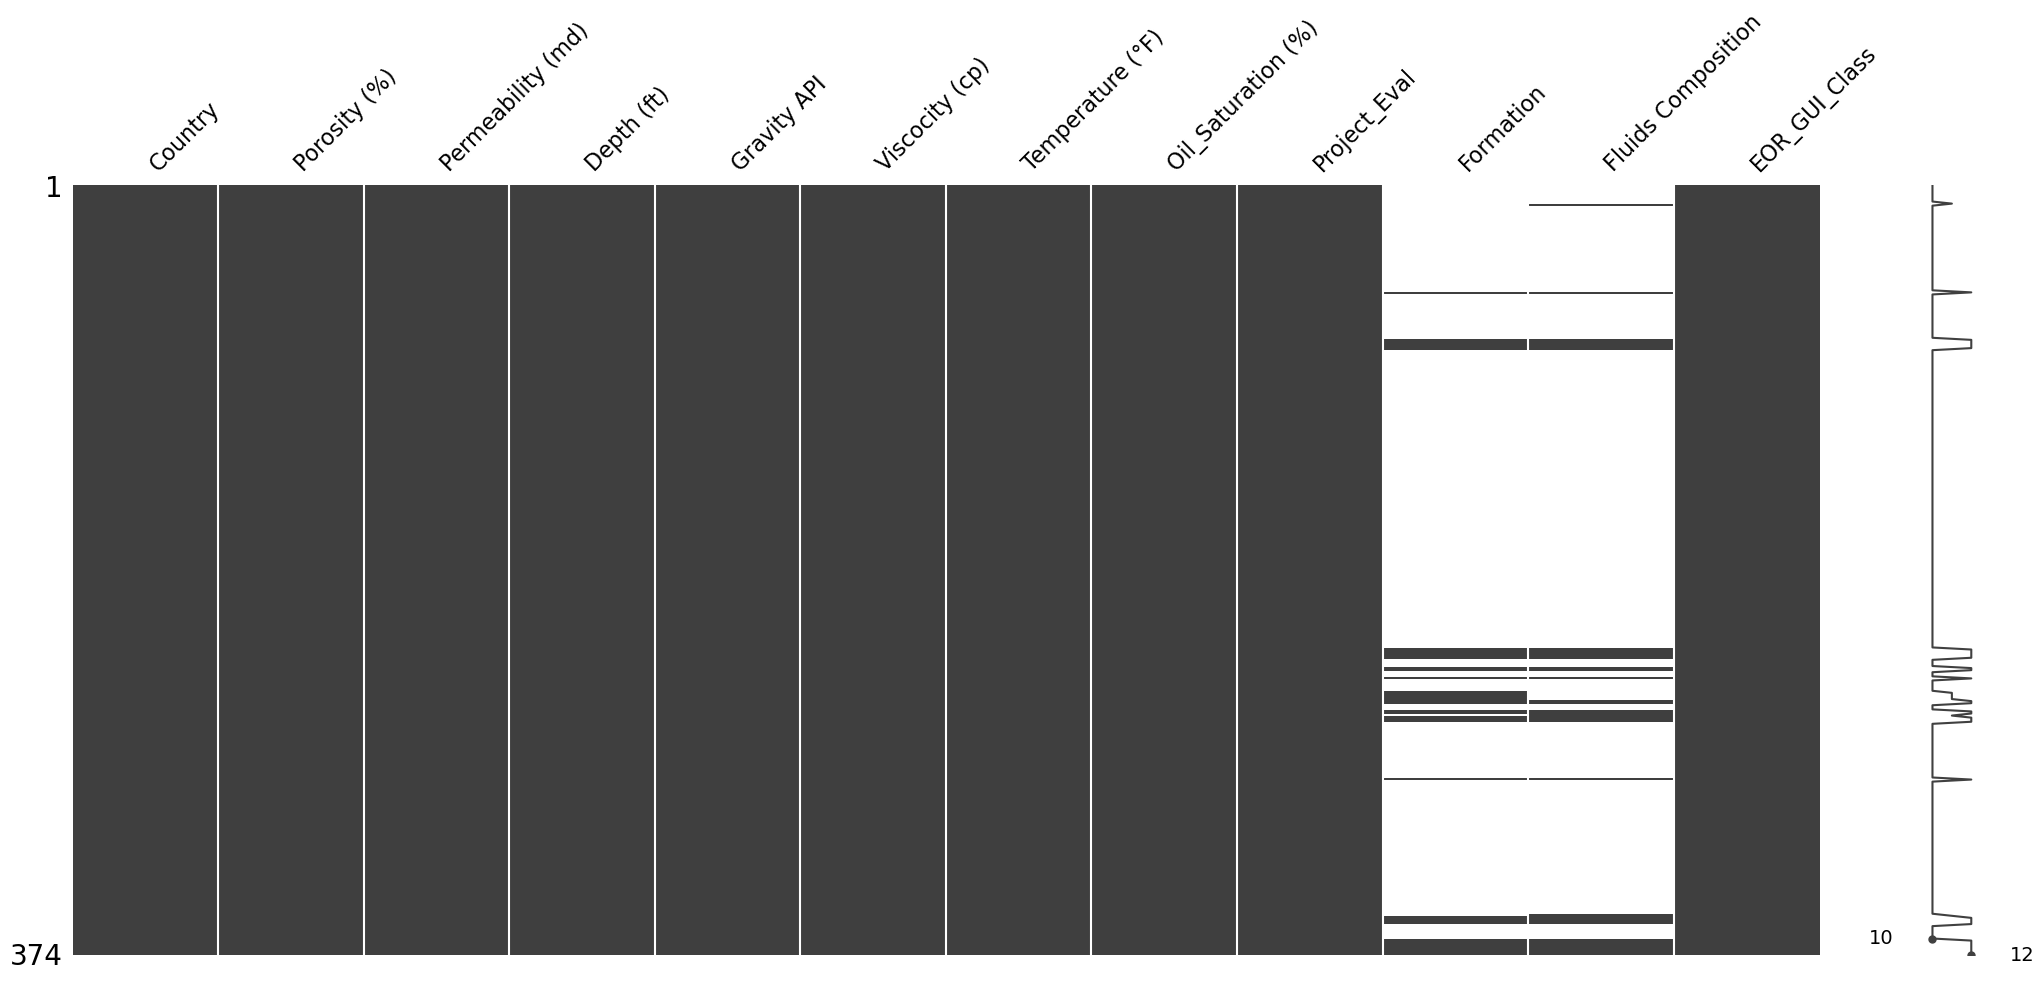

In [492]:
mso.matrix(data_clean)

plt.show()

In [493]:
suspected_values = data_clean.loc[
    # Físicamente inválidos
    (data_clean["Viscocity (cp)"] <= 0)
    | (data_clean["Porosity (%)"] > 100)
    | (data_clean["Temperature (°F)"] <= 0)
    | (data_clean["Oil_Saturation (%)"] > 100)
    | (data_clean["Gravity API"] > 70)
    

    # Posibles, pero extremos y sujetos a revisión
    | (data_clean["Depth (ft)"] < 500)
    | (data_clean["Depth (ft)"] > 30000)
    | (data_clean["Viscocity (cp)"] > 100000)
    | (data_clean["Temperature (°F)"] > 500)
    | (data_clean["Oil_Saturation (%)"] <= 10),
]

suspected_values

,Country,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition,EOR_GUI_Class
8,Canada,26.5,3000.0,1800.0,8.0,300000.0,63.0,70.0,Successful,NaN,NaN,Steam
12,Canada,33.0,7000.0,1600.0,10.0,500000.0,55.0,85.0,Successful,NaN,NaN,Steam
17,Canada,32.0,2000.0,1395.0,10.0,200000.0,55.0,70.0,Average,NaN,NaN,Steam
22,Canada,32.0,3500.0,1600.0,12.0,200000.0,60.0,60.0,Successful,NaN,NaN,Steam
69,Germany,38.0,1600.0,350.0,22.0,350.0,100.0,60.0,Successful,NaN,NaN,Steam
119,USA,40.3,3048.0,175.0,12.7,2200.0,75.0,55.0,Average,NaN,NaN,Steam
120,USA,39.2,955.0,300.0,13.9,1000.0,80.0,48.0,Average,NaN,NaN,Steam
135,USA,40.0,2000.0,200.0,13.0,3500.0,82.0,60.0,Successful,NaN,NaN,Steam
216,USA,32.0,650.0,400.0,19.0,660.0,129.8,94.0,Average,NaN,NaN,Combustion
232,USA,22.0,500.0,250.0,17.6,2900.0,55.0,60.0,Unsuccessful,NaN,NaN,Steam


### 3.1.6 Check for Outliers

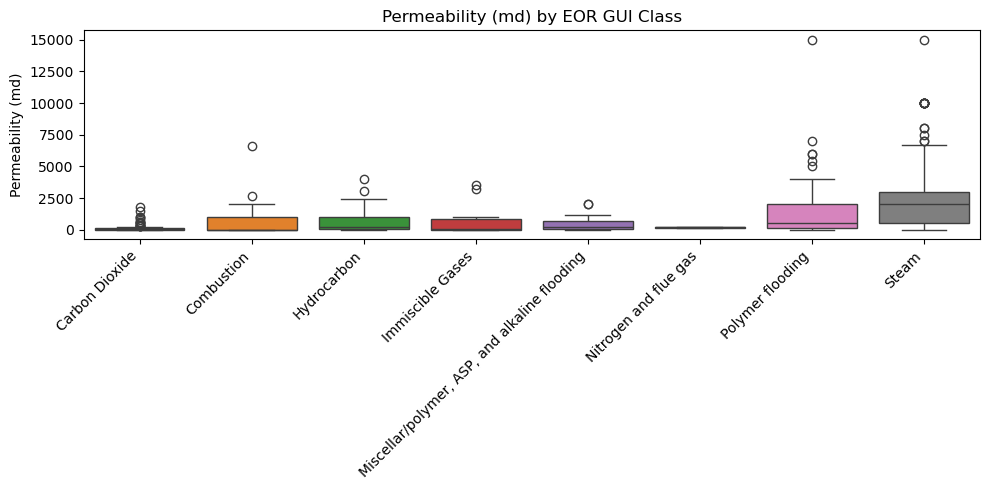

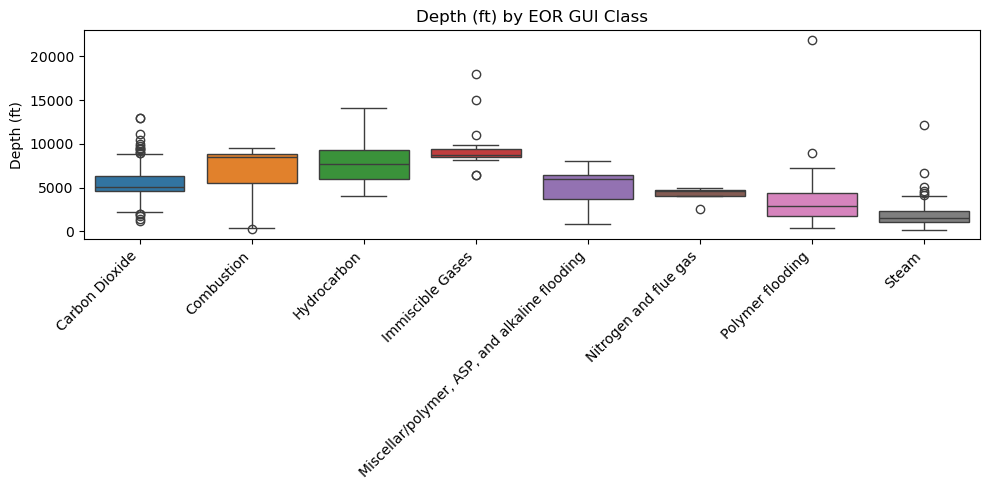

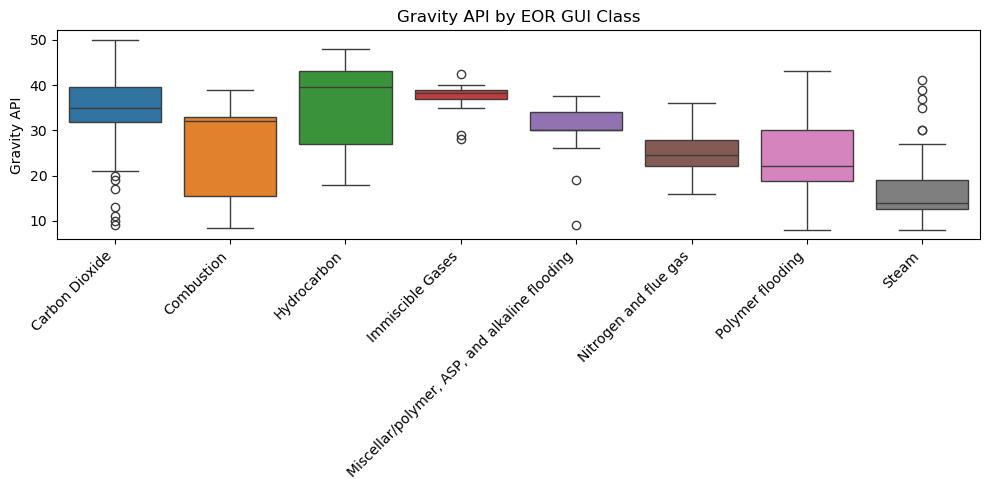

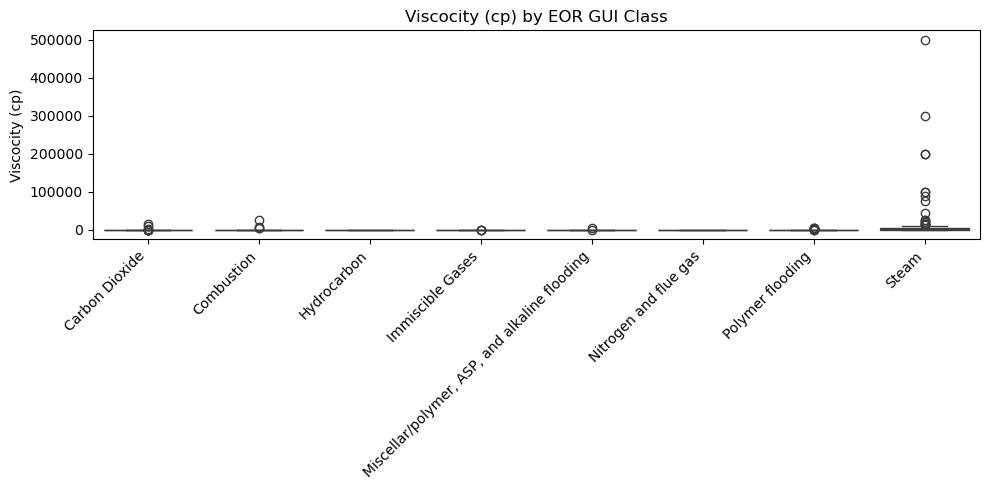

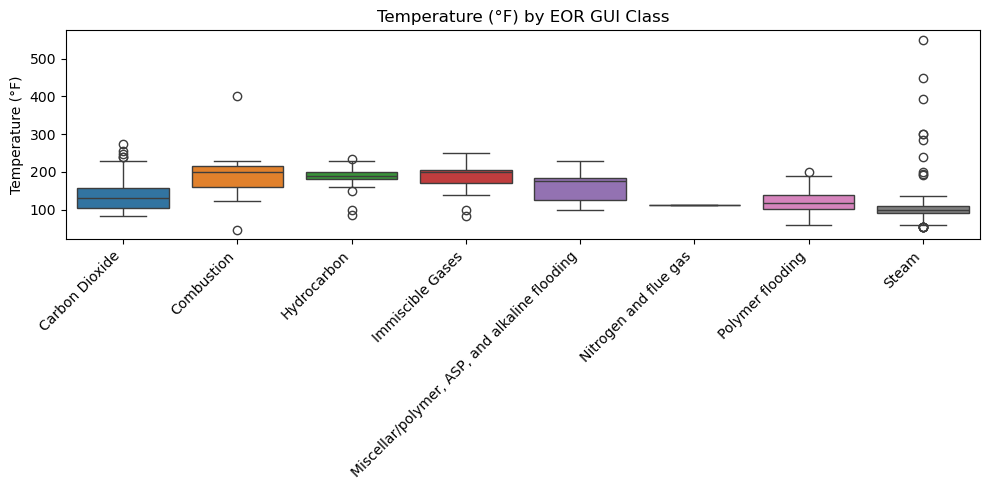

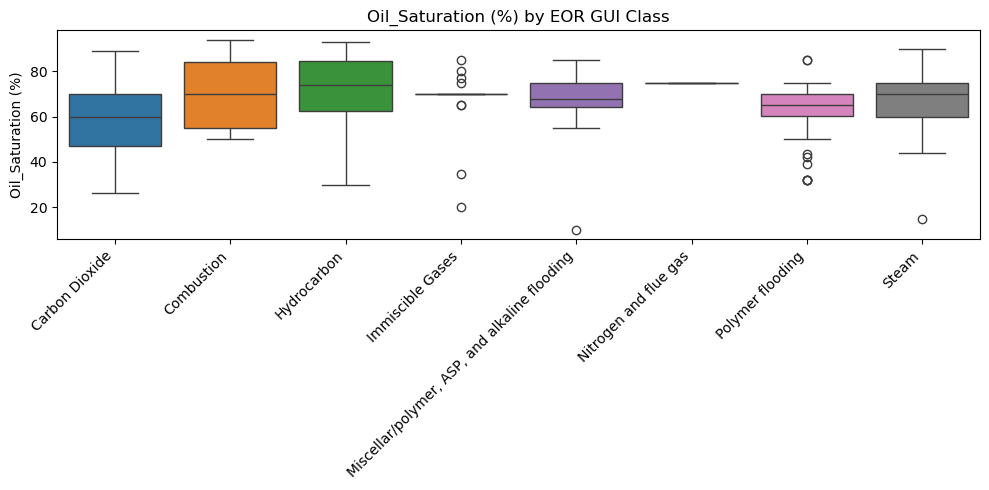

In [494]:
# Build box plots

numerical_columns = [
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

for column in numerical_columns:
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.boxplot(
        data=data_clean,
        x="EOR_GUI_Class",
        y=column, ax=ax, hue="EOR_GUI_Class"
    )

    ax.set_title(f"{column} by EOR GUI Class")
    ax.set_xlabel("")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [495]:
data_clean

,Country,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%),Project_Eval,Formation,Fluids Composition,EOR_GUI_Class
0,Brazil,27.0,3000.0,2300.0,13.0,825.00,124.0,76.0,Successful,NaN,NaN,Steam
1,Brazil,25.0,4000.0,1150.0,15.0,1700.00,100.0,70.0,Successful,NaN,NaN,Steam
2,Brazil,25.0,3000.0,1480.0,15.0,2500.00,100.0,70.0,Successful,NaN,NaN,Steam
3,Brazil,22.0,200.0,2460.0,21.0,500.00,122.0,70.0,Successful,NaN,NaN,Steam
4,Brazil,22.0,112.0,1970.0,35.0,105.00,120.0,50.0,Successful,NaN,NaN,Carbon Dioxide
...,...,...,...,...,...,...,...,...,...,...,...,...
413,Malaysia,23.0,750.0,9000.0,40.0,1.25,220.0,70.0,Unsuccessful,Sandstone,Volátiles (C1 - C7),Carbon Dioxide
414,Malaysia,23.0,850.0,8500.0,37.0,3.00,200.0,70.0,Average,Sandstone,Volátiles (C1 - C7),Immiscible Gases
415,Malaysia,30.0,200.0,8723.0,38.3,0.95,202.0,85.0,Average,Sandstone,Volátiles (C1 - C7),Immiscible Gases
416,Turkey,15.0,30.0,4500.0,13.0,800.00,155.0,85.0,Average,Carbonate,Fracciones pesados (C5 - C12),Carbon Dioxide


## 3.1. Feature Codification

In [496]:
# Remove class with insufficient observations
data_clean = data_clean[data_clean["EOR_GUI_Class"] != "Nitrogen and flue gas"].copy()

data_clean["EOR_GUI_Class"] = (
        data_clean["EOR_GUI_Class"]
        .cat.remove_unused_categories()
    )


# Check frecuency for each class
data_clean.EOR_GUI_Class.value_counts()


EOR_GUI_Class
Steam                                            123
Carbon Dioxide                                   116
Polymer flooding                                  49
Hydrocarbon                                       32
Combustion                                        19
Immiscible Gases                                  17
Miscellar/polymer, ASP, and alkaline flooding     14
Name: count, dtype: int64

In [497]:
# Define predictor and target variables

numeric_features = [
    "Porosity (%)",
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

X = data_clean[numeric_features].copy()

y = data_clean["EOR_GUI_Class"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.value_counts())

X shape: (370, 7)
y shape: (370,)


,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
0,27.0,3000.0,2300.0,13.0,825.0,124.0,76.0
1,25.0,4000.0,1150.0,15.0,1700.0,100.0,70.0
2,25.0,3000.0,1480.0,15.0,2500.0,100.0,70.0
3,22.0,200.0,2460.0,21.0,500.0,122.0,70.0
4,22.0,112.0,1970.0,35.0,105.0,120.0,50.0


EOR_GUI_Class
Steam                                            123
Carbon Dioxide                                   116
Polymer flooding                                  49
Hydrocarbon                                       32
Combustion                                        19
Immiscible Gases                                  17
Miscellar/polymer, ASP, and alkaline flooding     14
Name: count, dtype: int64

In [498]:
# Label target variable

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

display(y_encoded)

array([6, 6, 6, 6, 0, 6, 0, 0, 6, 6, 0, 0, 6, 6, 0, 2, 2, 6, 0, 0, 2, 6,
       6, 6, 6, 6, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       5, 5, 6, 0, 0, 0, 0, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5,
       5, 4, 6, 0, 6, 6, 6, 6, 6, 5, 0, 3, 3, 3, 6, 6, 6, 6, 0, 6, 6, 2,
       2, 2, 5, 6, 6, 6, 0, 5, 0, 0, 0, 0, 0, 2, 2, 0, 0, 6, 6, 6, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 5, 5, 5, 6, 6, 6,
       6, 1, 0, 0, 0, 6, 6, 5, 2, 2, 5, 5, 5, 6, 1, 3, 5, 5, 6, 0, 6, 5,
       6, 6, 5, 6, 3, 3, 0, 4, 5, 4, 5, 5, 4, 5, 3, 3, 3, 1, 4, 6, 6, 6,
       6, 4, 0, 0, 0, 0, 6, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 1, 5, 6, 5,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 6, 6, 6, 5, 5,

In [499]:
# Set training and testing set

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 296
Testing observations: 74


In [500]:
# Check labels of classes

for i, class_name in enumerate(encoder.classes_):
    print(i, "->", class_name)

0 -> Carbon Dioxide
1 -> Combustion
2 -> Hydrocarbon
3 -> Immiscible Gases
4 -> Miscellar/polymer, ASP, and alkaline flooding
5 -> Polymer flooding
6 -> Steam


## 3.2. Feature Scaling

In [501]:
# Clasess Balancing

# smote = SMOTE(
#     sampling_strategy={
#         "Combustion": 30,
#         'Miscellar/polymer, ASP, and alkaline flooding': 30,
#         'Immiscible Gases': 30
#     },
#     k_neighbors=3,
#     random_state=42
# )

In [502]:
# X_train_smote, y_train_smote = smote.fit_resample(
#     X_train,
#     y_train
# )

# print("Antes de SMOTE:")
# print(y_train.value_counts())

# print("\nDespués de SMOTE:")
# print(y_train_smote.value_counts())

In [503]:
# Function to scale variables for MLP model

def scale_numeric_features(X_train, X_test, numeric_features):
    """
    Escala las variables numéricas para entrenar el modelo MLP.
    El escalador se ajusta únicamente con los datos de entrenamiento.
    """

    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    log_features = [
    "Permeability (md)",
    "Viscocity (cp)"]

    for feature in log_features:
        X_train_scaled[feature] = np.log10(X_train[feature])

        X_test_scaled[feature] = np.log10(X_test[feature])
    
    scaler = RobustScaler()

    X_train_scaled[numeric_features] = scaler.fit_transform(
        X_train[numeric_features]
    )

    X_test_scaled[numeric_features] = scaler.transform(
        X_test[numeric_features]
    )

    return X_train_scaled, X_test_scaled, scaler

In [504]:
# Call scale_numeric_features

numeric_features = [
    "Porosity (%)",
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]

X_train_mlp, X_test_mlp, scaler = scale_numeric_features(X_train, X_test, numeric_features)

In [505]:
X_train_mlp[numeric_features].describe()

,Porosity (%),Permeability (md),Depth (ft),Gravity API,Viscocity (cp),Temperature (°F),Oil_Saturation (%)
count,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000,296.000000
mean,0.017923,0.678139,0.056093,-0.040363,6.856288,0.225971,-0.091056
std,0.920382,1.495094,0.646451,0.577363,39.046014,0.766330,0.739174
min,-1.454545,-0.170065,-0.841170,-0.997368,-0.023398,-0.945000,-2.800000
25%,-0.563636,-0.149660,-0.535005,-0.576316,-0.019805,-0.275000,-0.550000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.436364,0.850340,0.464995,0.423684,0.980195,0.725000,0.450000
max,5.454545,10.034014,2.884013,1.213158,501.868544,5.350000,1.400000


## 3.3. Feature Selection

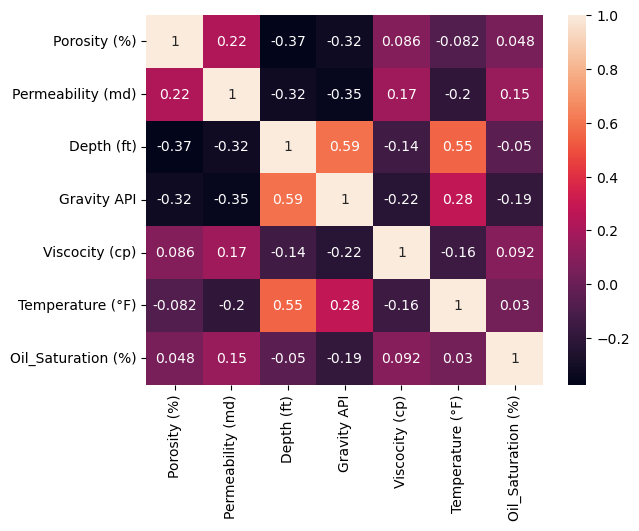

In [506]:
# get Correlation Matrix with Pearson method

cor = data_clean.corr(numeric_only=True)

sns.heatmap(cor, annot=True)
plt.show()

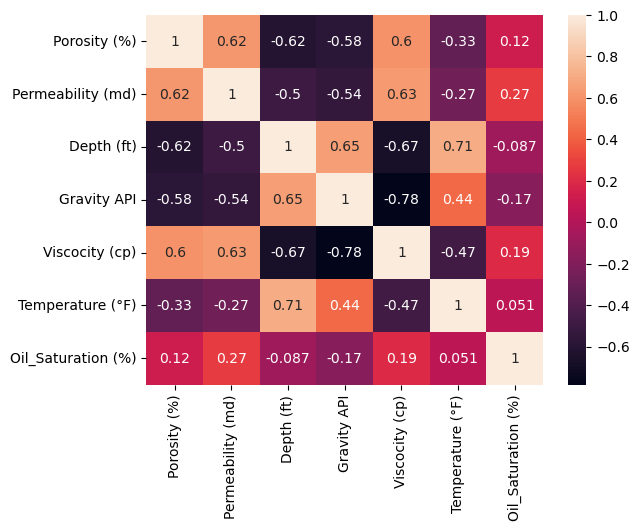

In [507]:
# Correlation matrix with spearman method

cor = data_clean.corr(numeric_only=True, method="spearman")

sns.heatmap(cor, annot=True)
plt.show()

In [508]:
# Anova Test to check relation of predictor variables with target variable

selector = SelectKBest(score_func=f_classif, k=6)
selector.fit(X_train, y_train)

results = pd.DataFrame({"feature": X_train.columns,
                       "F_score": selector.scores_,
                       "p_value": selector.pvalues_,
                       "selected": selector.get_support()})

results.sort_values(by="F_score", ascending=False, inplace=True)
results

,feature,F_score,p_value,selected
3,Gravity API,56.685563,4.807745e-46,True
2,Depth (ft),55.473175,2.530665e-45,True
1,Permeability (md),12.428772,1.858148e-12,True
5,Temperature (°F),10.973673,5.134054e-11,True
0,Porosity (%),9.429479,1.846528e-09,True
6,Oil_Saturation (%),6.159458,4.280007e-06,True
4,Viscocity (cp),2.732121,1.346568e-02,False


In [509]:
# Set variables for model

X_train = X_train.drop(columns="Porosity (%)")
X_train_mlp = X_train_mlp.drop(columns="Porosity (%)")

X_test = X_test.drop(columns="Porosity (%)")
X_test_mlp = X_test_mlp.drop(columns="Porosity (%)")

## 3.4. Class Balancing

In [ ]:
# Class Balancing

smote = SMOTE(
    sampling_strategy={
        1: 30,
        3: 30,
        4: 30
    },
    k_neighbors=3,
    random_state=42
)

In [ ]:
# Set balanced features

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Antes de SMOTE:")
print(y_train.shape)

print("\nDespués de SMOTE:")
print(y_train_smote.shape)

In [ ]:
numeric_features = [
    "Permeability (md)",
    "Depth (ft)",
    "Gravity API",
    "Viscocity (cp)",
    "Temperature (°F)",
    "Oil_Saturation (%)"
]


# Scale numeric features for mlp model
X_train_mlp, X_test_mlp, scaler = scale_numeric_features(X_train_smote, X_test, numeric_features)

---

# 4. Models Training and Evaluation

In [514]:
# Function to train each model

def train_and_tune(
    model,
    param_grid,
    X_train,
    y_train,
    search="random",
    scoring={
        "F1_macro": "f1_macro",
        "Balanced_accuracy": "balanced_accuracy"
    },
    cv=5,
    n_iter=20
):
    """
    Entrena un modelo y realiza tuneo de hiperparámetros.

    Parameters
    ----------
    model:
        Modelo o Pipeline de scikit-learn.

    param_grid:
        Diccionario con los hiperparámetros a evaluar.

    X_train, y_train:
        Datos de entrenamiento.

    search:
        "grid" para GridSearchCV.
        "random" para RandomizedSearchCV.

    scoring:
        Métrica utilizada para seleccionar el mejor modelo.

    cv:
        Número de particiones de validación cruzada.

    n_iter:
        Número de combinaciones para RandomizedSearchCV.

    Returns
    -------
    best_model:
        Mejor modelo ya entrenado.

    search_result:
        Objeto completo de GridSearchCV o RandomizedSearchCV.
    """

    cross_validation = RepeatedStratifiedKFold(
        n_splits=cv,
        n_repeats=3,
        random_state=42
    )

    if search.lower() == "grid":

        tuner = GridSearchCV(
            estimator=model,
            param_grid=param_grid,
            scoring=scoring,
            cv=cross_validation,
            n_jobs=-1,
            refit=True,
            return_train_score=True
        )

    elif search.lower() == "random":

        tuner = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=n_iter,
            scoring=scoring,
            cv=cross_validation,
            random_state=42,
            n_jobs=-1,
            refit=True,
            return_train_score=True
        )

    else:
        raise ValueError(
            "El método de búsqueda debe ser 'grid' o 'random'."
        )

    tuner.fit(X_train, y_train)

    print("Mejores hiperparámetros:")
    print(tuner.best_params_)

    print(f"\nMejor {scoring} en validación cruzada:")
    print(round(tuner.best_score_, 4))

    return tuner.best_estimator_, tuner

In [515]:
# Function to validate each model

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    print(
        "Balanced accuracy:",
        round(
            balanced_accuracy_score(y_test, y_pred),
            4
        )
    )

    print(
        "F1-macro:",
        round(
            f1_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),
            4
        )
    )

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    return y_pred

---

## 4.1. Training with Decision Tree Model

In [516]:
# Training with Decision Tree model

# Set the model
dt = DecisionTreeClassifier(class_weight="balanced",random_state=42)

# Set the hiperparam#eters space
dt_params = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10, 12, 15],
    "min_samples_split": [2, 4, 5, 6, 8, 10],
    "min_samples_leaf": [1, 2, 3, 4],
    "criterion": ["gini", "entropy", "log_loss"]
}

# Train the model
best_dt, dt_search = train_and_tune(
    model=dt,
    param_grid=dt_params,
    X_train=X_train_smote,
    y_train=y_train_smote,
    search="grid",
    scoring="f1_macro",
    cv=5
)

best_dt

Mejores hiperparámetros:
{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2}

Mejor f1_macro en validación cruzada:
0.6583


DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42)

In [517]:
# Model evaluation

y_pred_dt = evaluate_model(best_dt, X_test, y_test)
y_pred_dt

Balanced accuracy: 0.614
F1-macro: 0.5467

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.39      0.51        23
           1       0.67      1.00      0.80         4
           2       0.67      0.67      0.67         6
           3       0.33      0.33      0.33         3
           4       0.20      0.67      0.31         3
           5       0.31      0.40      0.35        10
           6       0.88      0.84      0.86        25

    accuracy                           0.61        74
   macro avg       0.54      0.61      0.55        74
weighted avg       0.68      0.61      0.62        74



array([4, 6, 6, 6, 0, 6, 6, 5, 6, 5, 6, 5, 2, 0, 4, 0, 4, 5, 0, 6, 5, 6,
       6, 5, 5, 6, 6, 0, 1, 6, 4, 5, 0, 0, 3, 4, 2, 4, 5, 3, 2, 0, 4, 1,
       6, 6, 5, 6, 6, 5, 5, 1, 1, 6, 6, 1, 6, 1, 6, 4, 0, 6, 2, 3, 4, 6,
       4, 0, 6, 2, 2, 0, 5, 0])

## 4.2. Training with Random Forest

In [518]:
# Training with Random Forest model

# set the model
rf = RandomForestClassifier(class_weight="balanced_subsample",random_state=42,n_jobs=-1)

# Set the hiperparameters space
rf_params = {
    "n_estimators": [50, 75, 100, 150, 200, 300],
    "max_depth": [4, 6, 8, 10, 12, 15, None],
    "min_samples_split": [2, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "max_features": ["sqrt", "log2"]
}

# Train the model
best_rf, rf_search = train_and_tune(
    model=rf,
    param_grid=rf_params,
    X_train=X_train_smote,
    y_train=y_train_smote,
    search="random",
    scoring="f1_macro",
    cv=5,
    n_iter=30
)

best_rf

Mejores hiperparámetros:
{'n_estimators': 75, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}

Mejor f1_macro en validación cruzada:
0.7203


RandomForestClassifier(class_weight='balanced_subsample', max_depth=15,
                       n_estimators=75, n_jobs=-1, random_state=42)

In [519]:
# Model evaluation

y_pred_rf = evaluate_model(best_rf, X_test, y_test)
y_pred_rf

Balanced accuracy: 0.658
F1-macro: 0.6879

Classification report:
              precision    recall  f1-score   support

           0       0.61      0.83      0.70        23
           1       1.00      1.00      1.00         4
           2       1.00      0.83      0.91         6
           3       0.25      0.33      0.29         3
           4       1.00      0.33      0.50         3
           5       0.67      0.40      0.50        10
           6       0.96      0.88      0.92        25

    accuracy                           0.76        74
   macro avg       0.78      0.66      0.69        74
weighted avg       0.79      0.76      0.76        74



array([0, 6, 6, 6, 0, 6, 6, 0, 6, 0, 6, 5, 0, 0, 0, 0, 0, 0, 0, 6, 0, 6,
       6, 5, 0, 6, 6, 0, 1, 6, 0, 0, 0, 0, 3, 4, 2, 5, 0, 3, 2, 0, 0, 1,
       6, 5, 0, 6, 6, 5, 0, 1, 0, 6, 6, 6, 2, 1, 6, 0, 0, 6, 2, 3, 0, 6,
       0, 0, 6, 3, 2, 0, 5, 0])

## 4.3. Training with XgBoost Model

In [520]:
##### Training with XgBoost Model

# Set the model
xgb = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Set the hiperparameters space
xgb_params = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7, 10],
    "gamma": [0, 0.1, 0.3, 0.5],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 2, 5, 10]
}

# Train the model
best_xgb, xgb_search = train_and_tune(
    model=xgb,
    param_grid=xgb_params,
    X_train=X_train_smote,
    y_train=y_train_smote,
    search="random",
    scoring="f1_macro",
    cv=5,
    n_iter=30
)

best_xgb

Mejores hiperparámetros:
{'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0.01, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.8}

Mejor f1_macro en validación cruzada:
0.71


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=0.1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
              max_leaves=None, min_child_weight=3, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=-1, num_parallel_tree=None, objective='multi:softprob', ...)

In [521]:
# Model evaluation

y_pred_xgb = evaluate_model(best_xgb, X_test, y_test)
y_pred_xgb

Balanced accuracy: 0.7199
F1-macro: 0.731

Classification report:
              precision    recall  f1-score   support

           0       0.68      0.83      0.75        23
           1       1.00      1.00      1.00         4
           2       0.83      0.83      0.83         6
           3       0.67      0.67      0.67         3
           4       0.50      0.33      0.40         3
           5       0.62      0.50      0.56        10
           6       0.96      0.88      0.92        25

    accuracy                           0.78        74
   macro avg       0.75      0.72      0.73        74
weighted avg       0.79      0.78      0.78        74



array([0, 6, 6, 6, 0, 6, 6, 0, 6, 0, 6, 5, 4, 0, 0, 0, 0, 5, 0, 6, 5, 6,
       6, 5, 0, 6, 6, 0, 1, 6, 0, 0, 5, 0, 3, 4, 2, 5, 0, 0, 2, 0, 0, 1,
       6, 5, 0, 6, 6, 5, 0, 1, 3, 6, 6, 6, 2, 1, 6, 0, 0, 6, 2, 3, 0, 6,
       0, 0, 6, 2, 2, 0, 0, 0])

## 4.4. Training with ANN

In [522]:
# Training with ANN Model

# set the model
mlp = MLPClassifier(
    max_iter=1500,
    random_state=42
)

# Set the hyperparameters space
mlp_params = {
    "hidden_layer_sizes": [
        (8,),
        (16,),
        (32,),
        (16,8),
        (32, 16),
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01, 0.1, 0.5, 1],
    "learning_rate_init": [0.0001, 0.0005, 0.001, 0.005, 0.01],
    "solver": ["adam"]
}

# Train the model
best_mlp, mlp_search = train_and_tune(
    model=mlp,
    param_grid=mlp_params,
    X_train=X_train_mlp,
    y_train=y_train_smote,
    search="random",
    scoring="f1_macro",
    cv=5,
    n_iter=25
)

best_mlp

Mejores hiperparámetros:
{'solver': 'adam', 'learning_rate_init': 0.01, 'hidden_layer_sizes': (32, 16), 'alpha': 0.1, 'activation': 'tanh'}

Mejor f1_macro en validación cruzada:
0.6781


MLPClassifier(activation='tanh', alpha=0.1, hidden_layer_sizes=(32, 16),
              learning_rate_init=0.01, max_iter=1500, random_state=42)

In [523]:
# Model Evaluation

y_pred_mlp = evaluate_model(best_mlp, X_test_mlp, y_test)
y_pred_mlp

Balanced accuracy: 0.6566
F1-macro: 0.6785

Classification report:
              precision    recall  f1-score   support

           0       0.67      0.78      0.72        23
           1       1.00      1.00      1.00         4
           2       0.80      0.67      0.73         6
           3       0.25      0.33      0.29         3
           4       1.00      0.33      0.50         3
           5       0.60      0.60      0.60        10
           6       0.96      0.88      0.92        25

    accuracy                           0.76        74
   macro avg       0.75      0.66      0.68        74
weighted avg       0.78      0.76      0.76        74



array([0, 6, 6, 6, 0, 6, 6, 0, 6, 5, 6, 5, 2, 0, 0, 0, 0, 5, 0, 5, 0, 6,
       6, 5, 0, 5, 6, 0, 1, 6, 0, 0, 0, 0, 3, 4, 2, 5, 5, 3, 2, 0, 0, 1,
       6, 5, 0, 6, 6, 6, 5, 1, 0, 6, 6, 6, 2, 1, 6, 0, 0, 6, 2, 3, 0, 6,
       0, 0, 6, 3, 6, 0, 0, 0])

## 4.5. Training with Stacking Classifier

In [524]:
# Training with Stacking model

stacking = StackingClassifier(
    estimators=[
        ("rf", best_rf),
        ("xgb", best_xgb)
    ],
    final_estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)


# Set hyperparameters space
stacking_params = {
    "final_estimator__C": [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10],
    "final_estimator__solver": ["lbfgs"],
    "passthrough": [False, True]
}

# Train the model
best_stacking, stacking_search = train_and_tune(
    model=stacking,
    param_grid=stacking_params,
    X_train=X_train_smote,
    y_train=y_train_smote,
    search="grid",
    scoring="f1_macro",
    cv=5
)

best_stacking

Mejores hiperparámetros:
{'final_estimator__C': 0.5, 'final_estimator__solver': 'lbfgs', 'passthrough': False}

Mejor f1_macro en validación cruzada:
0.7327


StackingClassifier(cv=3,
                   estimators=[('rf',
                                RandomForestClassifier(class_weight='balanced_subsample',
                                                       max_depth=15,
                                                       n_estimators=75,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=0.8, device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False...
                                              max_cat_to_onehot=None,
                                              max_delta_step=None, max_depth=2,
                                              max_leaves=None,
                                              min_child_weight=3, missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=500, n_jobs=-1,
                                              num_parallel_tree=None,
                                              objective='multi:softprob', ...))],
                   final_estimator=LogisticRegression(C=0.5,
                                                      class_weight='balanced',
                                                      max_iter=2000),
                   n_jobs=-1, stack_method='predict_proba')

In [525]:
# Model Evaluation

y_pred_stack = evaluate_model(best_stacking, X_test, y_test)
y_pred_stack

Balanced accuracy: 0.7075
F1-macro: 0.7043

Classification report:
              precision    recall  f1-score   support

           0       0.68      0.74      0.71        23
           1       1.00      1.00      1.00         4
           2       0.83      0.83      0.83         6
           3       0.50      0.67      0.57         3
           4       0.50      0.33      0.40         3
           5       0.50      0.50      0.50        10
           6       0.96      0.88      0.92        25

    accuracy                           0.76        74
   macro avg       0.71      0.71      0.70        74
weighted avg       0.76      0.76      0.76        74



array([0, 6, 6, 6, 0, 6, 6, 0, 6, 0, 6, 5, 4, 0, 0, 0, 0, 5, 0, 6, 5, 6,
       6, 5, 0, 6, 6, 0, 1, 6, 0, 0, 5, 0, 3, 4, 2, 5, 0, 3, 2, 0, 0, 1,
       6, 5, 0, 6, 6, 5, 5, 1, 3, 6, 6, 6, 2, 1, 6, 0, 0, 6, 2, 3, 0, 6,
       0, 0, 6, 2, 2, 0, 5, 0])

# 5. Final Results

In [526]:
def models_scores(models, y_train, y_test):

    results = []

    for name, (model, searh_cv, X_train, X_test) in models.items():

        # Predictions
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

        # Metrics
        results.append({
            "Model": name,

            "F1_Macro_Train": f1_score(
                y_train,
                y_pred_train,
                average="macro",
                zero_division=0
            ),

            "F1_Macro_CV": searh_cv.best_score_,

            "F1_Macro_Test":
                f1_score(
                    y_test,
                    y_pred_test,
                    average="macro",
                    zero_division=0
                ),

            "Balanced_Accuracy_Train": balanced_accuracy_score(
                y_train,
                y_pred_train
            ),

            "Balanced_Accuracy_Test":
                balanced_accuracy_score(
                    y_test,
                    y_pred_test
                )
        })

    return pd.DataFrame(results)

In [534]:
models = {
    "Decision Tree": (
        best_dt,
        dt_search,
        X_train_smote,
        X_test
    ),

    "Random Forest": (
        best_rf,
        rf_search,
        X_train_smote,
        X_test
    ),

    "XGBoost": (
        best_xgb,
        xgb_search,
        X_train_smote,
        X_test
    ),

    "MLP": (
        best_mlp,
        mlp_search,
        X_train_mlp,
        X_test_mlp
    ),

    "Stacking": (
        best_stacking,
        stacking_search,
        X_train_smote,
        X_test
    )
}

In [535]:
scores = models_scores(
    models,
    y_train_smote,
    y_test
)

scores.sort_values(by=["F1_Macro_CV"], ascending=[False])

,Model,F1_Macro_Train,F1_Macro_CV,F1_Macro_Test,Balanced_Accuracy_Train,Balanced_Accuracy_Test
4,Stacking,0.997419,0.732679,0.704252,0.998464,0.707495
1,Random Forest,0.997419,0.720287,0.687882,0.998464,0.658012
2,XGBoost,0.997419,0.709963,0.731046,0.998464,0.719917
3,MLP,0.985966,0.678077,0.678522,0.988581,0.656563
0,Decision Tree,0.836224,0.658308,0.546707,0.854986,0.613996


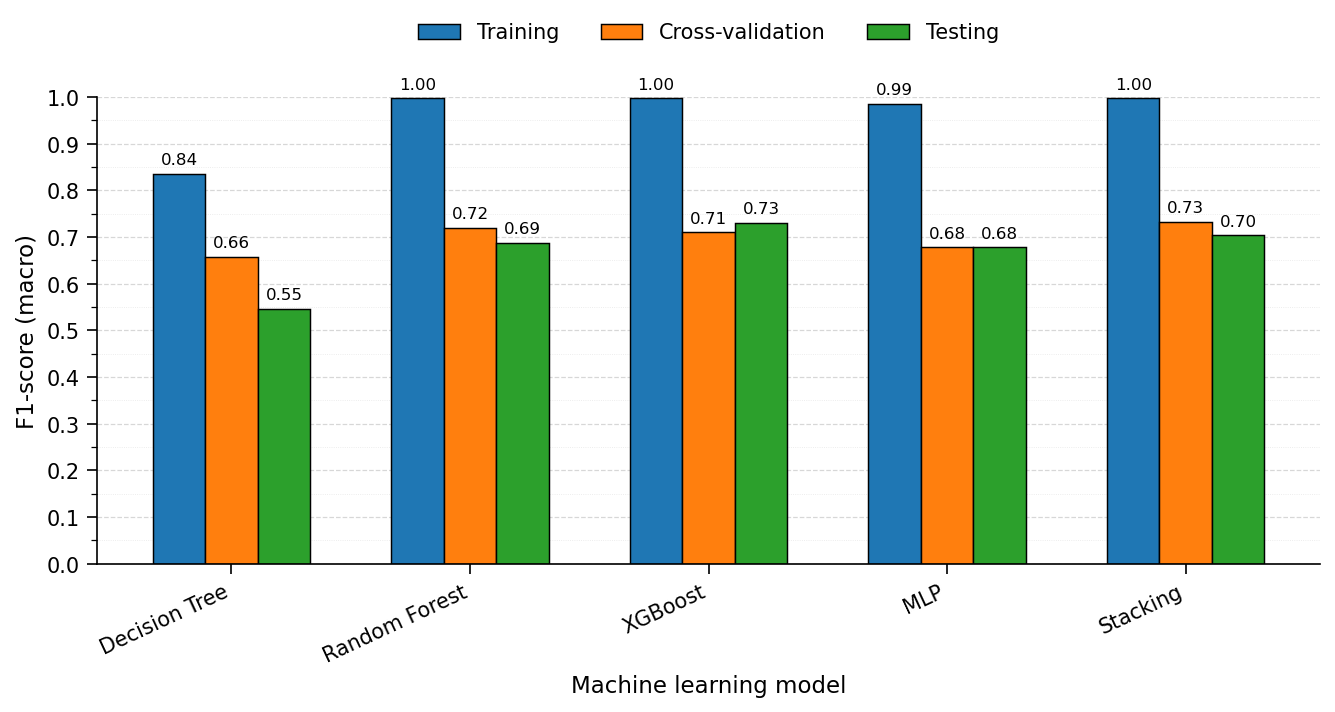

In [536]:

# Data

models = scores["Model"].to_numpy()

f1_train = scores["F1_Macro_Train"].to_numpy()
f1_cv  = scores["F1_Macro_CV"].to_numpy()
f1_test = scores["F1_Macro_Test"].to_numpy()

x = np.arange(len(models))
width = 0.22


# Figure and axes

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)



# Bars

bars_train = ax.bar(
    x - width,
    f1_train,
    width=width,
    label="Training",
    edgecolor="black",
    linewidth=0.7
)

bars_cv = ax.bar(
    x,
    f1_cv,
    width,
    label="Cross-validation",
    edgecolor="black",
    linewidth=0.7
)

bars_test = ax.bar(
    x + width,
    f1_test,
    width=width,
    label="Testing",
    edgecolor="black",
    linewidth=0.7
)



# Axes

ax.set_xlabel("Machine learning model", fontsize=11)
ax.set_ylabel("F1-score (macro)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(
    models,
    rotation=25,
    ha="right"
)

ax.set_ylim(0, 1.0)



# Major and minor ticks

ax.yaxis.set_major_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.05))

ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.xaxis.set_minor_locator(NullLocator())

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=5,
    width=0.8,
    labelsize=10
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="out",
    length=3,
    width=0.6
)



# Grid

ax.grid(
    axis="y",
    which="major",
    linestyle="--",
    linewidth=0.6,
    alpha=0.5
)

ax.grid(
    axis="y",
    which="minor",
    linestyle=":",
    linewidth=0.4,
    alpha=0.3
)

ax.set_axisbelow(True)



# Values over bars

ax.bar_label(
    bars_train,
    fmt="%.2f",
    padding=3,
    fontsize=8
)

ax.bar_label(
    bars_cv,
    fmt="%.2f",
    padding=3,
    fontsize=8
)

ax.bar_label(
    bars_test,
    fmt="%.2f",
    padding=3,
    fontsize=8
)



# Legend

ax.legend(
    frameon=False,
    fontsize=10,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
)



# Spines

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)



# Final layout

fig.tight_layout()

plt.show()